# Analyse exploratoire, nettoyage et réduction de dimensionnalité : Breast Cancer Wisconsin

Jeu de données : 569 tumeurs, 30 mesures sur des noyaux cellulaires et un diagnostic (M = maligne, B = bénigne).

**Fil conducteur** : on veut entraîner un perceptron à prédire le diagnostic. Pour cela, on prépare les données en trois temps :
1. **Comprendre** les données (étapes 1 à 5)
2. **Nettoyer** et exporter (étapes 6 et 7)
3. **Préparer pour le modèle** (étapes 8 à 11)

Plan :
1. Chargement et structure
2. Qualité des données
3. Répartition des classes
4. Distributions et outliers
5. Corrélations
6. Nettoyage
7. Export
8. Séparation train/test
9. Standardisation
10. Réduction de dimensionnalité (PCA)
11. Jeu de données final pour le perceptron

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

## 1. Chargement et structure

In [2]:
df = pd.read_csv("data/bcw_data.csv")
print("Dimensions :", df.shape)
df.head()

Dimensions : (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

Les 30 variables sont 10 mesures (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), chacune en version `_mean`, `_se` (erreur standard) et `_worst` (pire valeur).

## 2. Qualité des données

In [4]:
manquantes = df.isna().sum()
print("Valeurs manquantes (colonnes concernées) :")
print(manquantes[manquantes > 0])
print()
print("Lignes dupliquées :", df.duplicated().sum())
print("id dupliqués      :", df["id"].duplicated().sum())
print("Valeurs de diagnosis :", df["diagnosis"].unique())

Valeurs manquantes (colonnes concernées) :
Unnamed: 32    569
dtype: int64

Lignes dupliquées : 0
id dupliqués      : 0
Valeurs de diagnosis : <StringArray>
['M', 'B']
Length: 2, dtype: str


`Unnamed: 32` est entièrement vide : c'est un artefact d'export, on la supprimera.

In [5]:
num = df.drop(columns=["id", "diagnosis", "Unnamed: 32"])

print("Valeurs négatives :", (num < 0).sum().sum())

zeros = (num == 0).sum()
print("\nZéros par colonne :")
print(zeros[zeros > 0])

Valeurs négatives : 0

Zéros par colonne :
concavity_mean          13
concave points_mean     13
concavity_se            13
concave points_se       13
concavity_worst         13
concave points_worst    13
dtype: int64


In [6]:
# Les zéros de concavité concernent-ils les mêmes lignes ? Quel diagnostic ?
lignes_zero = df[df["concavity_mean"] == 0]
print("Mêmes lignes pour concave points :", (lignes_zero["concave points_mean"] == 0).all())
print(lignes_zero["diagnosis"].value_counts())

Mêmes lignes pour concave points : True
diagnosis
B    13
Name: count, dtype: int64


Les 13 zéros sont les mêmes lignes, toutes bénignes : ce sont des cellules sans concavité, pas des valeurs manquantes. On les garde.

In [7]:
# Cohérence : la pire valeur ne doit jamais être inférieure à la moyenne
for f in ["radius", "texture", "perimeter", "area", "smoothness",
          "compactness", "concavity", "concave points", "symmetry", "fractal_dimension"]:
    n = (num[f + "_worst"] < num[f + "_mean"]).sum()
    print(f"{f:20s} worst < mean : {n}")

radius               worst < mean : 0
texture              worst < mean : 0
perimeter            worst < mean : 0
area                 worst < mean : 0
smoothness           worst < mean : 0
compactness          worst < mean : 0
concavity            worst < mean : 0
concave points       worst < mean : 0
symmetry             worst < mean : 0
fractal_dimension    worst < mean : 0


## 3. Répartition des classes

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    0.627
M    0.373
Name: count, dtype: float64


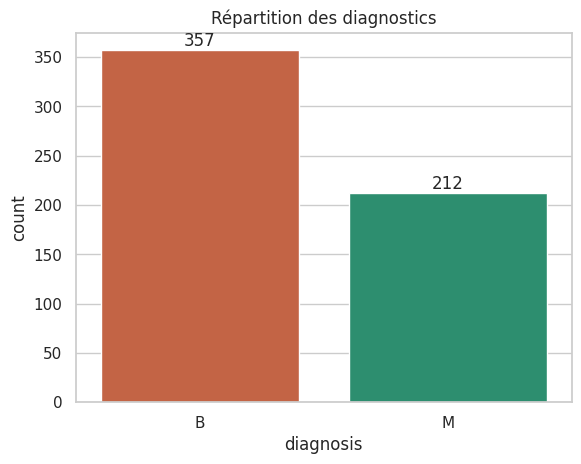

In [8]:
vc = df["diagnosis"].value_counts()
print(vc)
print((vc / len(df)).round(3))

ax = sns.countplot(data=df, x="diagnosis", hue="diagnosis", palette=["#1D9E75", "#D85A30"], order=["B", "M"], legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Répartition des diagnostics")
plt.show()

357 bénignes (62,7 %) contre 212 malignes (37,3 %) : déséquilibre modéré, acceptable pour un perceptron.

## 4. Distributions et outliers

In [9]:
num.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture_mean,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter_mean,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area_mean,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness_mean,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness_mean,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity_mean,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave points_mean,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry_mean,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
fractal_dimension_mean,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


In [10]:
# Asymétrie : les variables les plus déséquilibrées
num.skew().sort_values(ascending=False).head(8).round(2)

area_se                 5.45
concavity_se            5.11
fractal_dimension_se    3.92
perimeter_se            3.44
radius_se               3.09
smoothness_se           2.31
symmetry_se             2.20
compactness_se          1.90
dtype: float64

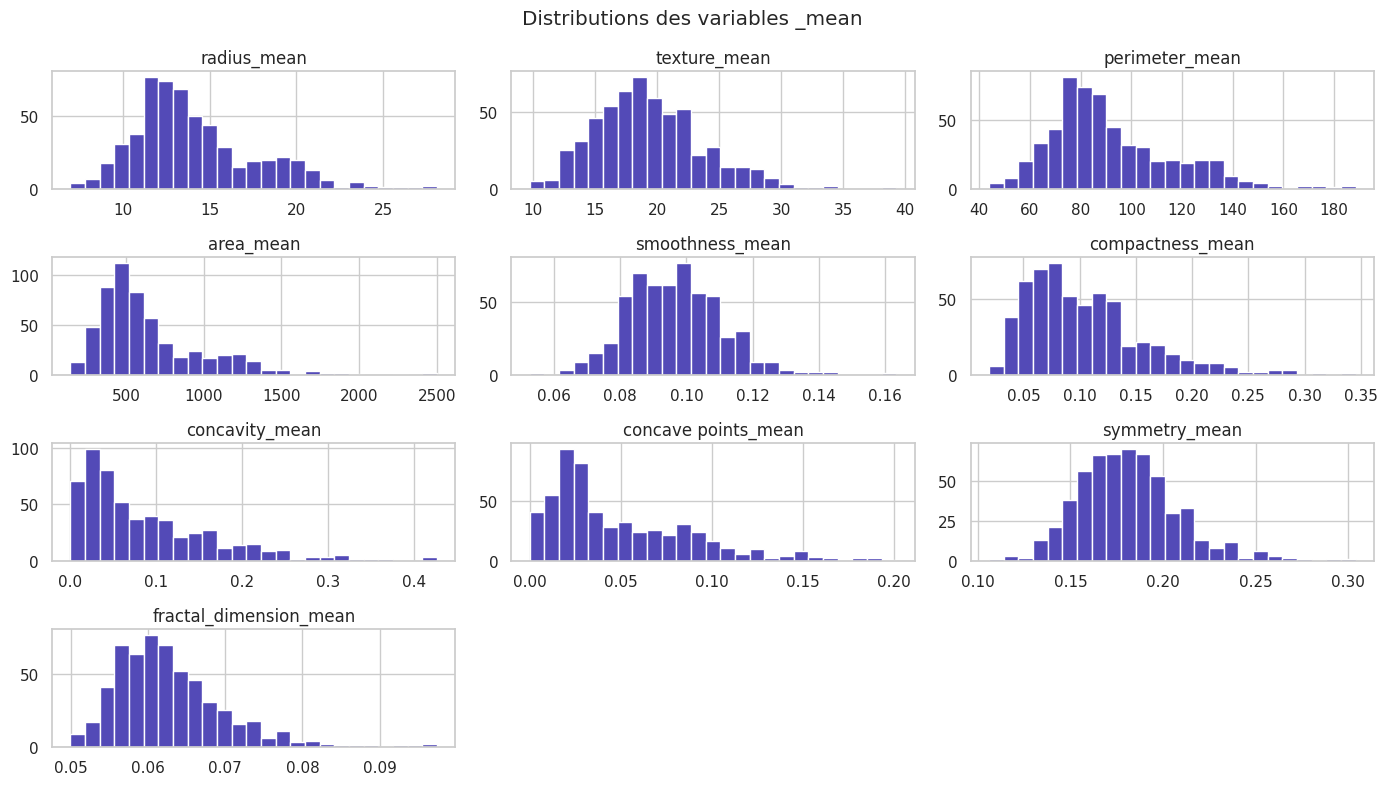

In [11]:
mean_cols = [c for c in num.columns if c.endswith("_mean")]
num[mean_cols].hist(bins=25, figsize=(14, 8), color="#534AB7")
plt.suptitle("Distributions des variables _mean")
plt.tight_layout()
plt.show()

In [12]:
# Outliers selon la règle de l'IQR (1,5 x IQR)
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
masque = (num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)

print("Outliers par colonne (top 10) :")
print(masque.sum().sort_values(ascending=False).head(10))
print("\nLignes avec au moins un outlier :", masque.any(axis=1).sum(), "sur", len(num))

Outliers par colonne (top 10) :
area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
dtype: int64

Lignes avec au moins un outlier : 171 sur 569


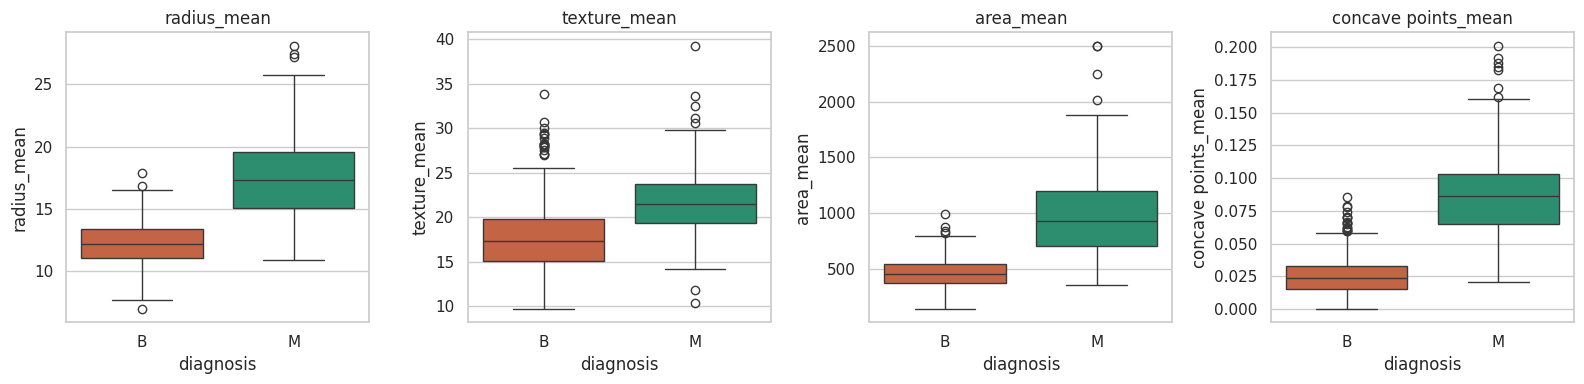

In [13]:
cols = ["radius_mean", "texture_mean", "area_mean", "concave points_mean"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(data=df, x="diagnosis", y=c, hue="diagnosis", order=["B", "M"],
                palette=["#1D9E75", "#D85A30"], legend=False, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

Les outliers sont de vraies mesures de tumeurs (souvent des cas malins de grande taille). On les **conserve** : les supprimer ferait perdre de l'information et fausserait l'analyse.

## 5. Corrélations

In [14]:
y = df["diagnosis"].map({"B": 0, "M": 1})
cor_cible = num.corrwith(y).sort_values(key=abs, ascending=False)
print("Top 10 corrélations avec le diagnostic (M = 1) :")
print(cor_cible.head(10).round(3))
print("\nPlus faibles :")
print(cor_cible.tail(5).round(3))

Top 10 corrélations avec le diagnostic (M = 1) :
concave points_worst    0.794
perimeter_worst         0.783
concave points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734
radius_mean             0.730
area_mean               0.709
concavity_mean          0.696
concavity_worst         0.660
dtype: float64

Plus faibles :
fractal_dimension_se      0.078
smoothness_se            -0.067
fractal_dimension_mean   -0.013
texture_se               -0.008
symmetry_se              -0.007
dtype: float64


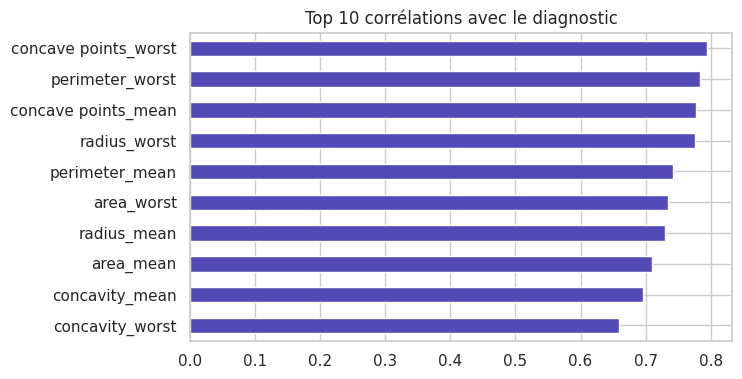

In [15]:
cor_cible.head(10)[::-1].plot.barh(color="#534AB7", figsize=(7, 4))
plt.title("Top 10 corrélations avec le diagnostic")
plt.show()

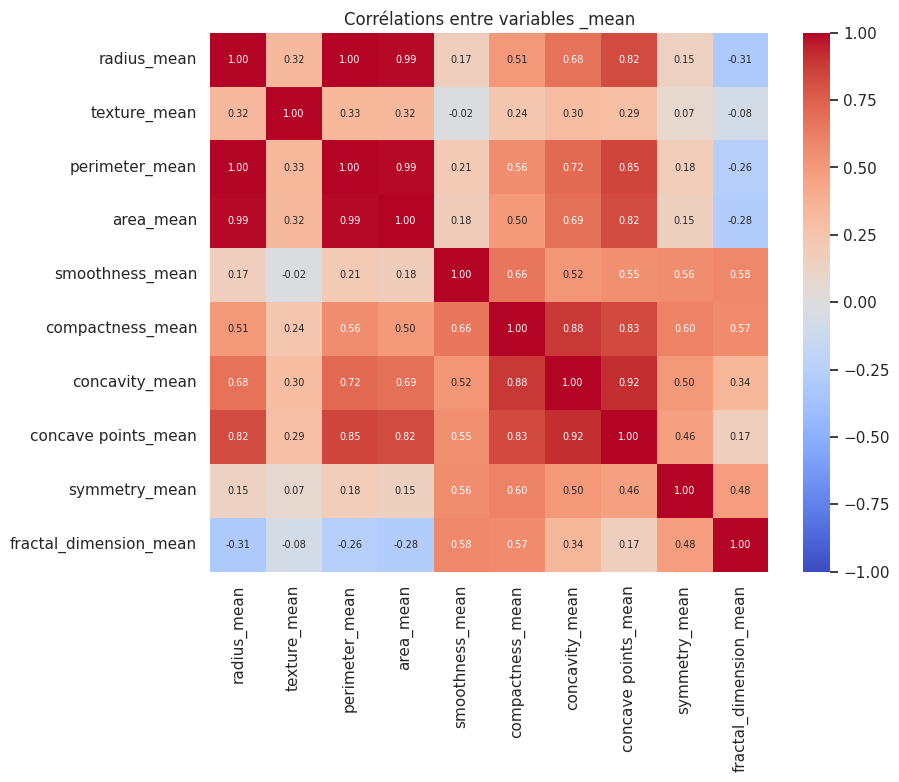

In [16]:
plt.figure(figsize=(9, 7))
sns.heatmap(num[mean_cols].corr(), cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Corrélations entre variables _mean")
plt.show()

In [17]:
# Multicolinéarité : paires fortement corrélées
cm = num.corr().abs()
paires = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("Paires avec |r| > 0,9 :", (paires > 0.9).sum())
paires.head(8).round(3)

Paires avec |r| > 0,9 : 21


radius_mean      perimeter_mean     0.998
radius_worst     perimeter_worst    0.994
radius_mean      area_mean          0.987
perimeter_mean   area_mean          0.987
radius_worst     area_worst         0.984
perimeter_worst  area_worst         0.978
radius_se        perimeter_se       0.973
perimeter_mean   perimeter_worst    0.970
dtype: float64

`radius`, `perimeter` et `area` sont quasi redondantes (r jusqu'à 0,998), ce qui est normal car la géométrie les relie. Pour un premier modèle simple, on peut n'en garder qu'une.

## 6. Nettoyage

1. Suppression de `Unnamed: 32` (colonne vide)
2. Encodage de `diagnosis` : B = 0, M = 1
3. Renommage de `concave points_*` en `concave_points_*` (pas d'espaces dans les noms)

On ne touche ni aux outliers ni aux zéros (voir plus haut). La normalisation se fera plus tard, après la séparation train/test, pour éviter la fuite de données.

In [18]:
df_clean = df.drop(columns=["Unnamed: 32"]).copy()
df_clean.columns = [c.replace(" ", "_") for c in df_clean.columns]
df_clean["diagnosis"] = df_clean["diagnosis"].map({"B": 0, "M": 1})

print("Dimensions :", df_clean.shape)
print("Valeurs manquantes :", df_clean.isna().sum().sum())
print(df_clean["diagnosis"].value_counts())
df_clean.head()

Dimensions : (569, 32)
Valeurs manquantes : 0
diagnosis
0    357
1    212
Name: count, dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 7. Export

In [19]:
df_clean.to_csv("bcw_data_clean.csv", index=False)
print("Fichier enregistré : bcw_data_clean.csv")

Fichier enregistré : bcw_data_clean.csv


### Où en est-on ?

À ce stade, `df_clean` contient 569 lignes et 30 variables numériques propres, avec le diagnostic encodé en 0/1. L'exploration a aussi révélé deux problèmes pour un modèle :

- **Les échelles sont très différentes** (`area_worst` monte à 4254, `smoothness_mean` ne dépasse pas 0,16)
- **Beaucoup de variables sont redondantes** (`radius`, `perimeter` et `area` ont une corrélation proche de 1)

Les étapes suivantes règlent ces deux points : on standardise (étape 9), puis on réduit le nombre de variables avec la PCA (étape 10).

## 8. Séparation train/test

On sépare d'abord les données en deux parties :

- **train (80 %)** : sert à apprendre (standardisation, PCA, puis perceptron)
- **test (20 %)** : sert uniquement à évaluer à la fin, comme s'il s'agissait de nouvelles tumeurs jamais vues

On le fait **avant** toute transformation. Si on standardisait ou on appliquait la PCA sur tout le jeu de données, le test influencerait l'apprentissage : c'est la **fuite de données** (data leakage), qui rend les résultats trop optimistes.

`stratify=y` garde la même proportion de tumeurs malignes dans les deux parties, ce qui est utile car les classes sont déséquilibrées (63 % / 37 %).

In [20]:
from sklearn.model_selection import train_test_split

# X = les 30 mesures (sans l'id, qui n'est pas une variable explicative)
# y = le diagnostic à prédire (0 = bénigne, 1 = maligne)
X = df_clean.drop(columns=["id", "diagnosis"])
y = df_clean["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20 % pour le test
    random_state=42,    # résultat reproductible
    stratify=y          # même proportion de classes dans train et test
)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Part de malignes - train :", round(y_train.mean(), 3), "| test :", round(y_test.mean(), 3))

Train : (455, 30) | Test : (114, 30)
Part de malignes - train : 0.374 | test : 0.368


Les deux parties ont bien la même proportion de tumeurs malignes (environ 37 %), grâce à `stratify`.

## 9. Standardisation

La PCA et le perceptron sont sensibles aux échelles : une variable comme `area_worst` (valeurs jusqu'à 4254) écraserait `smoothness_mean` (valeurs autour de 0,1) simplement parce que ses nombres sont plus grands.

La standardisation ramène chaque variable à une **moyenne de 0 et un écart-type de 1** :

`z = (x - moyenne) / écart-type`

Règle importante : on calcule la moyenne et l'écart-type **sur le train uniquement** (`fit_transform`), puis on applique ces mêmes valeurs au test (`transform`).

In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # apprend moyenne/écart-type sur le train, puis transforme
X_test_sc = scaler.transform(X_test)         # applique les valeurs du train au test

# Vérification : sur le train, moyenne ~ 0 et écart-type ~ 1
print("Moyenne max (en valeur absolue) :", abs(X_train_sc.mean(axis=0)).max().round(6))
print("Écart-type min / max :", X_train_sc.std(axis=0).min().round(3), "/", X_train_sc.std(axis=0).max().round(3))

Moyenne max (en valeur absolue) : 0.0
Écart-type min / max : 1.0 / 1.0


Toutes les variables sont maintenant sur la même échelle. On peut passer à la PCA.

## 10. Réduction de dimensionnalité (PCA)

**Idée** : la PCA (analyse en composantes principales) remplace les 30 variables par de nouvelles variables, les **composantes principales**. Chacune est une combinaison des variables d'origine, et elles sont classées par quantité d'information (variance) qu'elles portent. Comme les variables sont très corrélées ici, quelques composantes suffisent.

On procède en trois temps :
1. Regarder combien de variance chaque composante explique
2. Choisir le nombre de composantes à garder (seuil de 95 %)
3. Appliquer la PCA et visualiser le résultat

### 10.1 Variance expliquée

In [22]:
from sklearn.decomposition import PCA

# PCA complète (30 composantes) pour voir comment la variance se répartit
pca_full = PCA().fit(X_train_sc)
variance = pca_full.explained_variance_ratio_
cumul = np.cumsum(variance)

print("Variance expliquée par les 3 premières composantes :", variance[:3].round(3))
for seuil in (0.90, 0.95, 0.99):
    print(f"Composantes nécessaires pour {seuil:.0%} :", np.argmax(cumul >= seuil) + 1)

Variance expliquée par les 3 premières composantes : [0.446 0.185 0.096]
Composantes nécessaires pour 90% : 7
Composantes nécessaires pour 95% : 10
Composantes nécessaires pour 99% : 17


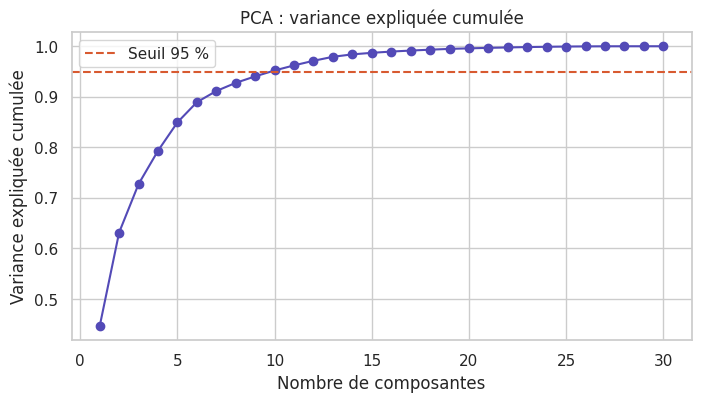

In [23]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumul) + 1), cumul, marker="o", color="#534AB7")
plt.axhline(0.95, color="#D85A30", linestyle="--", label="Seuil 95 %")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.title("PCA : variance expliquée cumulée")
plt.legend()
plt.show()

**Lecture** : la première composante porte à elle seule environ 45 % de l'information, et 10 composantes suffisent pour atteindre 95 %. On passe donc de 30 variables à 10, en perdant seulement 5 % de l'information.

### 10.2 Application de la PCA

In [24]:
# On garde le nombre de composantes qui expliquent 95 % de la variance
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_sc)   # apprentissage sur le train uniquement
X_test_pca = pca.transform(X_test_sc)         # le test est seulement projeté

print("Avant PCA :", X_train_sc.shape[1], "variables")
print("Après PCA :", X_train_pca.shape[1], "composantes")
print("Variance conservée :", pca.explained_variance_ratio_.sum().round(3))

Avant PCA : 30 variables
Après PCA : 10 composantes
Variance conservée : 0.952


### 10.3 Visualisation en 2D

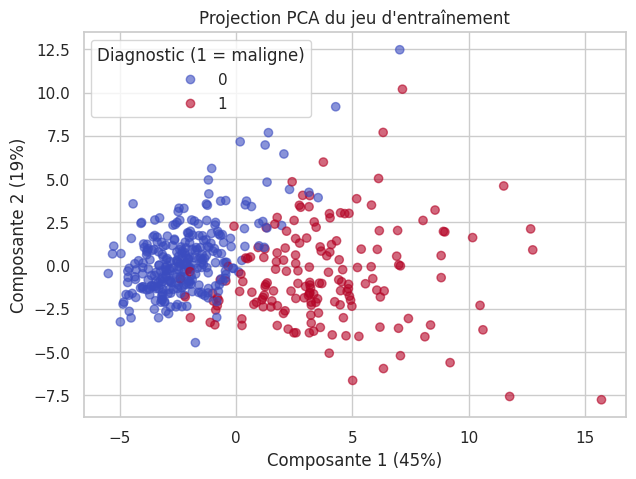

In [25]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap="coolwarm", alpha=0.6)
plt.xlabel(f"Composante 1 ({pca.explained_variance_ratio_[0]:.0%})")
plt.ylabel(f"Composante 2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.title("Projection PCA du jeu d'entraînement")
plt.legend(*scatter.legend_elements(), title="Diagnostic (1 = maligne)")
plt.show()

**Lecture** : avec seulement deux composantes, les tumeurs bénignes (bleu) et malignes (rouge) se séparent déjà nettement, avec un léger chevauchement au milieu. C'est un bon signe : le problème est presque **linéairement séparable**, ce qui convient à un perceptron.

### 10.4 Que représentent les composantes ?

In [26]:
# Poids des variables d'origine dans les deux premières composantes
loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=X.columns,
    columns=["PC1", "PC2"]
)

print("Variables qui pèsent le plus dans PC1 :")
print(loadings["PC1"].sort_values(key=abs, ascending=False).head(5).round(3))
print("\nVariables qui pèsent le plus dans PC2 :")
print(loadings["PC2"].sort_values(key=abs, ascending=False).head(5).round(3))

Variables qui pèsent le plus dans PC1 :
concave_points_mean     0.260
concavity_mean          0.258
concave_points_worst    0.249
compactness_mean        0.242
perimeter_worst         0.235
Name: PC1, dtype: float64

Variables qui pèsent le plus dans PC2 :
fractal_dimension_mean     0.367
fractal_dimension_worst    0.277
fractal_dimension_se       0.276
radius_mean               -0.240
area_mean                 -0.237
Name: PC2, dtype: float64


**Lecture** :

- **PC1** regroupe des mesures de forme irrégulière (`concave_points`, `concavity`, `compactness`) et de taille (`perimeter`). Elle représente en gros la **taille et l'irrégularité de la tumeur**, d'où son lien fort avec le diagnostic.
- **PC2** est dominée par `fractal_dimension` : elle capture surtout la **complexité du contour**.

Contrairement à Boruta, la PCA ne garde pas les variables d'origine : elle en crée de nouvelles. On perd donc un peu d'interprétabilité, mais on gagne en compacité et on élimine la redondance.

## 11. Jeu de données final pour le perceptron

Résumé de ce qu'on a produit :

| Objet | Contenu | Forme |
|---|---|---|
| `X_train_pca` | 10 composantes, jeu d'entraînement | (455, 10) |
| `X_test_pca` | 10 composantes, jeu de test | (114, 10) |
| `y_train`, `y_test` | diagnostics (0 ou 1) | 455 et 114 valeurs |

Le perceptron écrit en POO attend des **listes Python**, pas des tableaux numpy ni des Series pandas : on les convertit.

In [27]:
# Conversion en listes Python pour la classe Perceptron
X_train_list = X_train_pca.tolist()
X_test_list = X_test_pca.tolist()
y_train_list = y_train.tolist()
y_test_list = y_test.tolist()

print("Nombre d'entrées du perceptron :", len(X_train_list[0]))
print("Un exemple :", [round(v, 2) for v in X_train_list[0]], "->", y_train_list[0])

Nombre d'entrées du perceptron : 10
Un exemple : [-0.88, -2.57, -0.55, 1.64, -0.26, 0.11, 0.51, -0.21, -0.11, 0.42] -> 1


### Prochaine étape

Entraîner le perceptron sur `X_train_list` / `y_train_list`, puis mesurer la précision sur `X_test_list` / `y_test_list` :

```python
p = Perceptron(n_inputs=10)
p.train(X_train_list, y_train_list, epochs=50)
```

Pour une conclusion plus riche, on peut comparer la précision avec la PCA, avec les 30 variables standardisées, et avec une sélection de variables (Boruta).